# Milestone 3, Section 2: Robustness & Security (adversarial + noise)

Runs every experiment of Section 2 on the deployed same-story bi-encoder (`models/minilm_finetuned`, Milestone 2) and the
robust version trained here (`models/minilm_robust`). Code: `src/robustness.py`. Outputs: `outputs/milestone3/`
(CSVs + figures), which the report numbers are taken from.

* `SMOKE=1` runs everything on a few hundred pairs to check the code.
* `M3_RETRAIN=1` retrains `minilm_robust` even if it already exists.

In [16]:
import json, os, platform, sys, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, psutil
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data' / 'pairs').is_dir())
sys.path.insert(0, str(ROOT))
from src.robustness import *
import src.robustness as m3

SMOKE = os.environ.get('SMOKE', '0') == '1'
O = OUT / 'smoke' if SMOKE else OUT
(O / 'figures').mkdir(parents=True, exist_ok=True)
SEEDS = [SEED, SEED + 1, SEED + 2]                 # three noise draws per setting -> mean and std

P = load_pairs()
TRAIN, VAL, TEST = P['train'], P['val'], P['test']

# Reuse Milestone 2's outputs: its training recipe (v2 is trained with exactly the same one) and its recorded
# results (checked against this run below). Committed versions: git checkout origin/ege/milestone2/efficiency -- outputs/milestone2
M2 = load_m2()
if M2['config']:
    m3.CFG = {**m3.CFG, **M2['config']}
    assert M2.get('seed') in (None, SEED), f"Milestone 2 used seed {M2['seed']}, this code uses {SEED}"
    if M2.get('smoke'):
        print('WARNING: outputs/milestone2/train_config.json comes from a SMOKE run')
print('Milestone 2 recipe reused:', m3.CFG)
print('Milestone 2 files missing:', M2['missing'] or 'none')
if SMOKE:
    TRAIN = TRAIN.sample(600, random_state=SEED).reset_index(drop=True)
    VAL = VAL.sample(400, random_state=SEED).reset_index(drop=True)
    TEST = TEST.sample(400, random_state=SEED).reset_index(drop=True)
    m3.CFG = {**m3.CFG, 'epochs': 2}
HW = {'device': DEVICE, 'cpu': platform.processor() or platform.machine(), 'threads': torch.get_num_threads(),
      'gpu': torch.cuda.get_device_name(0) if DEVICE == 'cuda' else None, 'torch': torch.__version__,
      'sentence_transformers': sentence_transformers.__version__, 'smoke': SMOKE}
print(HW, {k: len(v) for k, v in dict(train=TRAIN, val=VAL, test=TEST).items()})

Milestone 2 recipe reused: {'epochs': 3, 'batch_size': 32, 'learning_rate': 2e-05, 'weight_decay': 0.01, 'warmup_ratio': 0.1, 'max_grad_norm': 1.0, 'max_seq_length': 128, 'margin': 0.5, 'freeze_word_embeddings': True, 'patience': 1}
Milestone 2 files missing: none
{'device': 'cuda', 'cpu': 'Intel64 Family 6 Model 151 Stepping 2, GenuineIntel', 'threads': 12, 'gpu': 'NVIDIA GeForce RTX 3060', 'torch': '2.14.1+cu126', 'sentence_transformers': '6.3.0', 'smoke': False} {'train': 21907, 'val': 2850, 'test': 2457}


## 2.1 Robustness methods

**Data level: noise augmentation (v2).** Same way as v1, but each training headline is, with
probability 0.5, given one natural corruption: typos (15% of words), word dropout (15%), accents stripped, case changed, or a
`LIVE:` / `EN DIRECT |` style prefix. A fresh draw is made every epoch. Homoglyphs, entity stuffing and the gradient attacks
are kept out of training, so they measure transfer to attacks the model never saw.

In [17]:
RETRAIN = os.environ.get('M3_RETRAIN', '0') == '1' or SMOKE
v2_path = (MODELS / 'exp' / 'minilm_robust_smoke') if SMOKE else V2_PATH
if RETRAIN or not v2_path.exists() or not (O / 'v2_train_config.json').exists():   # no record of how v2 was trained -> train it again
    run = train_biencoder(TRAIN, VAL, v2_path, aug_prob=0.5, cfg=m3.CFG)
    run['history'].to_csv(O / 'v2_training_history.csv', index=False)
    json.dump({'best_epoch': run['best_epoch'], 'minutes': run['minutes'], 'aug_prob': 0.5, 'config': m3.CFG,
               'base_model': str(BASE_MODEL), 'hardware': HW}, open(O / 'v2_train_config.json', 'w'), indent=2, default=str)
print(json.load(open(O / 'v2_train_config.json')))

{'best_epoch': 3, 'minutes': 3.3, 'aug_prob': 0.5, 'config': {'epochs': 3, 'batch_size': 32, 'learning_rate': 2e-05, 'weight_decay': 0.01, 'warmup_ratio': 0.1, 'max_grad_norm': 1.0, 'max_seq_length': 128, 'margin': 0.5, 'freeze_word_embeddings': True, 'patience': 1}, 'base_model': 'paraphrase-multilingual-MiniLM-L12-v2', 'hardware': {'device': 'cuda', 'cpu': 'Intel64 Family 6 Model 151 Stepping 2, GenuineIntel', 'threads': 12, 'gpu': 'NVIDIA GeForce RTX 3060', 'torch': '2.14.1+cu126', 'sentence_transformers': '6.3.0', 'smoke': False}}


**Model level: Platt calibration.** A cosine similarity is not a probability. We fit `p = sigmoid(a*s + b)` on the clean
validation scores (two parameters per model) so that the confidence the extension shows, and the abstention band below,
mean what they say.

**Inference level: sanitizer + abstention.** `sanitize()` applies NFKC, removes invisible format characters, maps Cyrillic /
Greek look-alike letters inside Latin words back to Latin, and strips live/opinion prefixes. Pairs whose calibrated
probability falls in a band around the threshold (sized on val to keep 90% of pairs) are not merged: the extension keeps
Google's own card for them.

**v1 = the deployed Milestone 2 model** (`models/minilm_finetuned`, the original model from the team Drive).
It is used as is, not retrained; the next cell checks that it reproduces the Milestone 2 results.

In [18]:
if not V1_PATH.exists():
    raise FileNotFoundError(f'{V1_PATH} not found. Copy minilm_finetuned (the Milestone 2 model) from the team Drive there.')
print('v1 from', V1_PATH, '(Milestone 2 model)')

v1 from C:\Users\Goldencami\Desktop\gitHub\Behind-the-Feed-Data-Challenge\models\minilm_finetuned (Milestone 2 model)


In [19]:
tfidf = Tfidf(TRAIN)
v1 = BiEncoder(V1_PATH, 'v1')
v2 = BiEncoder(v2_path, 'v2')
PIPES = {
    'TF-IDF': Pipeline(tfidf, name='TF-IDF'),
    'v1 (deployed)': Pipeline(v1, name='v1 (deployed)'),
    'v1 + sanitizer': Pipeline(v1, True, name='v1 + sanitizer'),
    'v2 (augmented)': Pipeline(v2, name='v2 (augmented)'),
    'v2 + sanitizer': Pipeline(v2, True, name='v2 + sanitizer'),
}
BASE = {'v1 + sanitizer': 'v1 (deployed)', 'v2 + sanitizer': 'v2 (augmented)'}
for name, p in PIPES.items():
    # same rule as Milestone 2 (best val F1); a sanitized pipeline keeps its model's threshold
    p.fit(VAL, threshold=PIPES[BASE[name]].threshold if name in BASE else None)
    p.band = abstain_band(p, VAL, 0.9)
    print(f'{p.name:16s} threshold {p.threshold:.3f}  Platt a={p.platt.coef_[0,0]:.2f} b={p.platt.intercept_[0]:.2f}  band {p.band[0]:.2f}-{p.band[1]:.2f}')
MAIN = ['v1 (deployed)', 'v2 + sanitizer']

# Is this the Milestone 2 model? It must reproduce M2's recorded val threshold and test F1.
CHECK = {}
for name, key in [('TF-IDF', 'TF-IDF'), ('v1 (deployed)', 'v1')]:
    ok, CHECK[name] = same_model_as_m2(PIPES[name], VAL, TEST, M2['pairs'].get(key)) if not SMOKE else (None, {})
    CHECK[name]['matches_milestone2'] = ok
    print(f"{name}: {'same as Milestone 2' if ok else 'NOT the same as Milestone 2' if ok is False else 'not checked'}", CHECK[name])
V1_IS_M2 = CHECK['v1 (deployed)']['matches_milestone2']
if V1_IS_M2 is False:
    print('\nWARNING: models/minilm_finetuned is not the model behind the Milestone 2 results (different threshold or test F1).'
          '\nResults are still valid for this v1, but they will not match the Milestone 2 report. To match it, use the'
          '\noriginal model folder from the RTX 3080 run.')

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

TF-IDF           threshold 0.042  Platt a=29.93 b=-1.63  band 0.32-0.50
v1 (deployed)    threshold 0.724  Platt a=23.51 b=-17.20  band 0.31-0.61
v1 + sanitizer   threshold 0.724  Platt a=23.49 b=-17.18  band 0.31-0.61
v2 (augmented)   threshold 0.763  Platt a=25.50 b=-19.27  band 0.38-0.71
v2 + sanitizer   threshold 0.763  Platt a=25.48 b=-19.26  band 0.38-0.71
TF-IDF: same as Milestone 2 {'threshold_m2': 0.0424, 'threshold_m3': 0.0424, 'test_f1_m2': 0.7679611650485437, 'test_f1_m3': 0.7679611650485437, 'test_pr_auc_m2': 0.8460440340854114, 'test_pr_auc_m3': 0.8460440340854114, 'matches_milestone2': True}
v1 (deployed): same as Milestone 2 {'threshold_m2': 0.7244, 'threshold_m3': 0.7244, 'test_f1_m2': 0.9058927000879508, 'test_f1_m3': 0.9058927000879508, 'test_pr_auc_m2': 0.9658139060055408, 'test_pr_auc_m3': 0.9658139060055408, 'matches_milestone2': True}


## 2.4a Clean test metrics (95% bootstrap CIs, 1,000 resamples)

In [20]:
y = TEST.label.values
CLEAN = {}
rows = []
for name, p in PIPES.items():
    s = p.raw(TEST.headline_a, TEST.headline_b); CLEAN[name] = s
    m = evaluate(y, s, p.threshold)
    lo, hi = bootstrap_ci(y, s, p.threshold, n=200 if SMOKE else 1000)
    prob = p.prob(s)
    e_platt, _ = ece(y, prob)
    e_raw, _ = ece(y, np.clip((s + 1) / 2, 0, 1)) if name != 'TF-IDF' else ece(y, np.clip(s, 0, 1))
    sel = selective(y, prob, s, p.threshold, p.band)
    row = {'model': name, **m, 'f1_lo': lo, 'f1_hi': hi, 'ece_raw': e_raw, 'ece_platt': e_platt, **sel}
    for ed in ['en-CA', 'fr-CA']:
        k = (TEST.edition == ed).values
        row[f'f1_{ed[:2]}'] = evaluate(y[k], s[k], p.threshold)['f1']
    rows.append(row)
clean = pd.DataFrame(rows); clean.to_csv(O / 'clean_metrics.csv', index=False)
clean.round(3)

,model,precision,recall,f1,accuracy,roc_auc,pr_auc,f1_lo,f1_hi,ece_raw,ece_platt,coverage,selective_f1,f1_en,f1_fr
0,TF-IDF,0.868,0.688,0.768,0.805,0.834,0.846,0.746,0.787,0.380,0.049,0.911,0.797,0.788,0.709
1,v1 (deployed),0.916,0.896,0.906,0.913,0.971,0.966,0.893,0.917,0.398,0.026,0.919,0.934,0.917,0.875
2,v1 + sanitizer,0.915,0.896,0.905,0.912,0.971,0.966,0.893,0.917,0.397,0.027,0.919,0.934,0.916,0.875
3,v2 (augmented),0.938,0.859,0.897,0.908,0.973,0.968,0.883,0.910,0.411,0.035,0.915,0.927,0.909,0.861
4,v2 + sanitizer,0.938,0.857,0.896,0.907,0.973,0.968,0.882,0.909,0.411,0.035,0.915,0.926,0.908,0.861


## 2.2 / 2.3 Natural corruptions and homoglyphs

Each corruption is applied to both headlines of every test pair (a corrupted feed affects everyone), three random draws per
strength. Threshold and calibration stay as fitted on clean val.

In [21]:
def score_condition(df, kind, strength, seed, rows, keep_scores=None):
    for name, p in PIPES.items():
        s = p.raw(df.headline_a, df.headline_b)
        m = evaluate(df.label.values, s, p.threshold)
        prob = p.prob(s)
        rows.append({'model': name, 'corruption': kind, 'strength': strength, 'seed': seed, **m,
                     'ece_platt': ece(df.label.values, prob)[0], **selective(df.label.values, prob, s, p.threshold, p.band)})
        if keep_scores is not None:
            keep_scores[(name, kind, strength, seed)] = s

rows, SCORES, PERTURBED = [], {}, {}
for name, p in PIPES.items():
    m = clean.set_index('model').loc[name]
    rows.append({'model': name, 'corruption': 'clean', 'strength': 0, 'seed': SEED, **{k: m[k] for k in
                 ['precision', 'recall', 'f1', 'accuracy', 'roc_auc', 'pr_auc', 'ece_platt', 'coverage', 'selective_f1']}})
t0 = time.time()
for kind, (fn, strengths) in CORRUPTIONS.items():
    for st in strengths:
        for seed in SEEDS:
            df = corrupt_df(TEST, fn, st, seed)
            if seed == SEED:
                PERTURBED[(kind, st)] = df
            score_condition(df, kind, st if st is not None else 1, seed, rows, SCORES if seed == SEED else None)
    print(f'{kind}: done ({time.time() - t0:.0f}s)')
rob = pd.DataFrame(rows); rob.to_csv(O / 'robustness_noise.csv', index=False)
summary = (rob.groupby(['corruption', 'strength', 'model']).agg(f1=('f1', 'mean'), f1_std=('f1', 'std'),
           pr_auc=('pr_auc', 'mean'), accuracy=('accuracy', 'mean'), ece=('ece_platt', 'mean'),
           coverage=('coverage', 'mean'), selective_f1=('selective_f1', 'mean')).reset_index())
summary.to_csv(O / 'robustness_noise_summary.csv', index=False)
summary.pivot_table(index=['corruption', 'strength'], columns='model', values='f1').round(3)

typos: done (86s)
word dropout: done (152s)
homoglyphs: done (212s)
accents stripped: done (216s)
case changed: done (224s)
prefix added: done (235s)


model                      TF-IDF  v1 (deployed)  v1 + sanitizer  \
corruption       strength                                          
accents stripped 1.0        0.761          0.910           0.910   
case changed     1.0        0.768          0.846           0.845   
clean            0.0        0.768          0.906           0.905   
homoglyphs       0.1        0.740          0.889           0.905   
                 0.2        0.710          0.875           0.905   
                 0.3        0.664          0.841           0.905   
                 0.5        0.533          0.795           0.905   
prefix added     1.0        0.744          0.907           0.905   
typos            0.1        0.745          0.886           0.886   
                 0.2        0.706          0.863           0.863   
                 0.3        0.661          0.836           0.836   
                 0.5        0.544          0.794           0.794   
word dropout     0.1        0.742          0.879           0.879   
                 0.2        0.698          0.845           0.844   
                 0.3        0.648          0.806           0.804   
                 0.5        0.521          0.691           0.691   

model                      v2 (augmented)  v2 + sanitizer  
corruption       strength                                  
accents stripped 1.0                0.903           0.902  
case changed     1.0                0.859           0.858  
clean            0.0                0.897           0.896  
homoglyphs       0.1                0.884           0.896  
                 0.2                0.870           0.896  
                 0.3                0.841           0.896  
                 0.5                0.799           0.896  
prefix added     1.0                0.900           0.896  
typos            0.1                0.880           0.880  
                 0.2                0.854           0.854  
                 0.3                0.834           0.834  
                 0.5                0.790           0.790  
word dropout     0.1                0.868           0.868  
                 0.2                0.833           0.832  
                 0.3                0.792           0.792  
                 0.5                0.685           0.684

## 2.2 Adversarial evaluation

Plausible adversaries (details in the report):
* **Black-box, no queries:** a publisher who wants its article grouped with a trending story (to share its card, or to take
  the lead slot our ranker gives to smaller outlets) adds that story's key terms to its own headline: **entity stuffing**.
* **Black-box with score access:** the same publisher queries the public extension/API and edits its headline word by word
  until the grouping changes: **greedy word edits**.
* **Invisible edits:** homoglyphs and zero-width characters (above), which change the model input but not what a reader sees.
* **White-box:** the 118 MB int8 fallback model ships inside the Chrome extension, so its weights are public: **FGSM / PGD**
  on the token embeddings (upper bound on what a gradient attacker can do).

In [22]:
rows = []
for k in [0, 1, 2, 3, 4]:
    df = entity_stuff(TEST, k)
    PERTURBED[('entity stuffing', k)] = df
    neg = (df.label == 0).values
    for name, p in PIPES.items():
        s = p.raw(df.headline_a, df.headline_b)
        SCORES[(name, 'entity stuffing', k, SEED)] = s
        m = evaluate(df.label.values, s, p.threshold)
        rows.append({'model': name, 'k_terms': k, 'f1': m['f1'], 'accuracy': m['accuracy'], 'precision': m['precision'],
                     'false_merge_rate': float((s[neg] >= p.threshold).mean())})
stuff = pd.DataFrame(rows); stuff.to_csv(O / 'attack_entity_stuffing.csv', index=False)
stuff.pivot(index='k_terms', columns='model', values='false_merge_rate').round(3)

model,TF-IDF,v1 (deployed),v1 + sanitizer,v2 (augmented),v2 + sanitizer
k_terms,,,,,
0,0.092,0.073,0.073,0.050,0.050
1,0.672,0.177,0.176,0.119,0.119
2,0.903,0.318,0.317,0.232,0.231
3,0.969,0.463,0.463,0.374,0.372
4,0.994,0.602,0.598,0.491,0.491


In [23]:
N_ATT = 40 if SMOKE else 200                     # pairs per label; each step queries the model once per candidate edit
att_df = pd.concat([TEST[TEST.label == 1].sample(N_ATT, random_state=SEED), TEST[TEST.label == 0].sample(N_ATT, random_state=SEED)])
rows, GREEDY = [], {}
for name in ['TF-IDF', 'v1 (deployed)', 'v1 + sanitizer', 'v2 + sanitizer']:
    t0 = time.time()
    g = greedy_attack(PIPES[name], att_df, max_edits=3)
    GREEDY[name] = g
    g.to_csv(O / f"attack_greedy_{name.split()[0].replace('-', '').lower()}{'_san' if 'sanitizer' in name else ''}.csv", index=False)
    for lab, d in g.groupby('label'):
        ok = d[d.correct_before]
        for e in [1, 2, 3]:
            flipped = (~ok.correct_after) & (ok.edits <= e)
            rows.append({'model': name, 'label': lab, 'max_edits': e, 'pairs_correct_before': len(ok),
                         'attack_success_rate': float(flipped.mean()) if len(ok) else np.nan,
                         'robust_accuracy': float((d.correct_before & ~((~d.correct_after) & (d.edits <= e))).mean()),
                         'mean_queries': float(ok.queries.mean())})
    print(f'{name}: {time.time() - t0:.0f}s')
greedy = pd.DataFrame(rows); greedy.to_csv(O / 'attack_greedy_summary.csv', index=False)
greedy.pivot_table(index=['label', 'max_edits'], columns='model', values='attack_success_rate').round(3)

TF-IDF: 1s
v1 (deployed): 11s
v1 + sanitizer: 11s
v2 + sanitizer: 11s


model            TF-IDF  v1 (deployed)  v1 + sanitizer  v2 + sanitizer
label max_edits                                                       
0     1           1.000          0.398           0.392           0.323
      2           1.000          0.640           0.634           0.599
      3           1.000          0.780           0.774           0.760
1     1           0.398          0.285           0.285           0.280
      2           0.654          0.575           0.575           0.601
      3           0.774          0.788           0.793           0.798

In [24]:
EPS = [0.0, 0.01, 0.02, 0.05, 0.1, 0.2]
rows = []
for name, enc in [('v1 (deployed)', v1), ('v2 (augmented)', v2)]:
    p = PIPES[name]
    for eps in EPS:
        for steps, method in [(1, 'FGSM'), (5, 'PGD-5')]:
            if eps == 0 and steps > 1:
                continue
            t0 = time.time()
            s = gradient_attack(enc, TEST, eps, steps)
            m = evaluate(TEST.label.values, s, p.threshold)
            rows.append({'model': name, 'method': method if eps else 'clean', 'eps': eps, **m, 'seconds': time.time() - t0})
grad = pd.DataFrame(rows); grad.to_csv(O / 'attack_gradient.csv', index=False)
grad.pivot_table(index=['method', 'eps'], columns='model', values='f1').round(3)

model        v1 (deployed)  v2 (augmented)
method eps                                
FGSM   0.01          0.888           0.884
       0.02          0.870           0.870
       0.05          0.822           0.820
       0.10          0.708           0.729
       0.20          0.535           0.528
PGD-5  0.01          0.888           0.884
       0.02          0.868           0.869
       0.05          0.808           0.810
       0.10          0.634           0.662
       0.20          0.282           0.284
clean  0.00          0.906           0.897

## 2.3 Robustness curves, confidence histograms, reliability diagrams

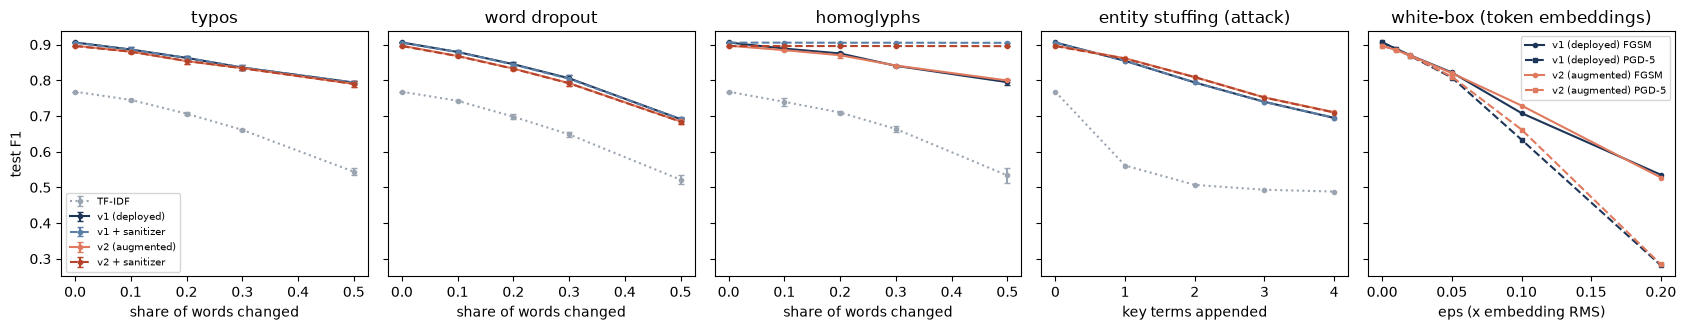

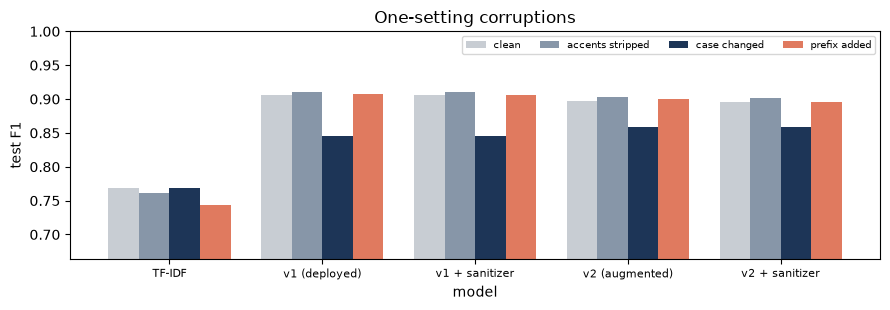

In [25]:
COL = {'TF-IDF': '#9aa5b1', 'v1 (deployed)': '#1d3557', 'v1 + sanitizer': '#5b7fa6', 'v2 (augmented)': '#e07a5f', 'v2 + sanitizer': '#b5432a'}
STY = {'TF-IDF': ':', 'v1 (deployed)': '-', 'v1 + sanitizer': '--', 'v2 (augmented)': '-', 'v2 + sanitizer': '--'}
clean_f1 = clean.set_index('model').f1
fig, axes = plt.subplots(1, 5, figsize=(17, 3.4), sharey=True)
for ax, kind in zip(axes, ['typos', 'word dropout', 'homoglyphs']):
    for name in PIPES:
        d = summary[(summary.corruption == kind) & (summary.model == name)].sort_values('strength')
        x, f, sd = [0] + d.strength.tolist(), [clean_f1[name]] + d.f1.tolist(), [0] + d.f1_std.fillna(0).tolist()
        ax.errorbar(x, f, yerr=sd, label=name, color=COL[name], ls=STY[name], marker='o', ms=3, capsize=2)
    ax.set(title=kind, xlabel='share of words changed')
axes[0].set_ylabel('test F1')
for name in PIPES:
    d = stuff[stuff.model == name]
    axes[3].plot(d.k_terms, d.f1, color=COL[name], ls=STY[name], marker='o', ms=3)
axes[3].set(title='entity stuffing (attack)', xlabel='key terms appended')
for name in ['v1 (deployed)', 'v2 (augmented)']:
    for method, mk in [('FGSM', 'o'), ('PGD-5', 's')]:
        d = grad[(grad.model == name) & grad.method.isin([method, 'clean'])].sort_values('eps')
        axes[4].plot(d.eps, d.f1, color=COL[name], marker=mk, ms=3, ls='-' if method == 'FGSM' else '--', label=f'{name} {method}')
axes[4].set(title='white-box (token embeddings)', xlabel='eps (x embedding RMS)'); axes[4].legend(fontsize=7)
axes[0].legend(fontsize=7, loc='lower left')
plt.tight_layout(); plt.savefig(O / 'figures' / 'robustness_curves.png', dpi=200); plt.show()

single = summary[summary.corruption.isin(['accents stripped', 'case changed', 'prefix added'])]
tab = single.pivot(index='corruption', columns='model', values='f1')
tab.loc['clean'] = clean_f1
tab = tab.loc[['clean', 'accents stripped', 'case changed', 'prefix added'], list(PIPES)]
ax = tab.T.plot.bar(figsize=(9, 3.2), color=['#c8cdd3', '#8796a8', '#1d3557', '#e07a5f'], width=0.8)
ax.set(ylabel='test F1', ylim=(max(0, tab.values.min() - 0.08), 1), title='One-setting corruptions'); plt.xticks(rotation=0, fontsize=8)
plt.legend(fontsize=7, ncol=4); plt.tight_layout(); plt.savefig(O / 'figures' / 'single_corruptions.png', dpi=200); plt.show()

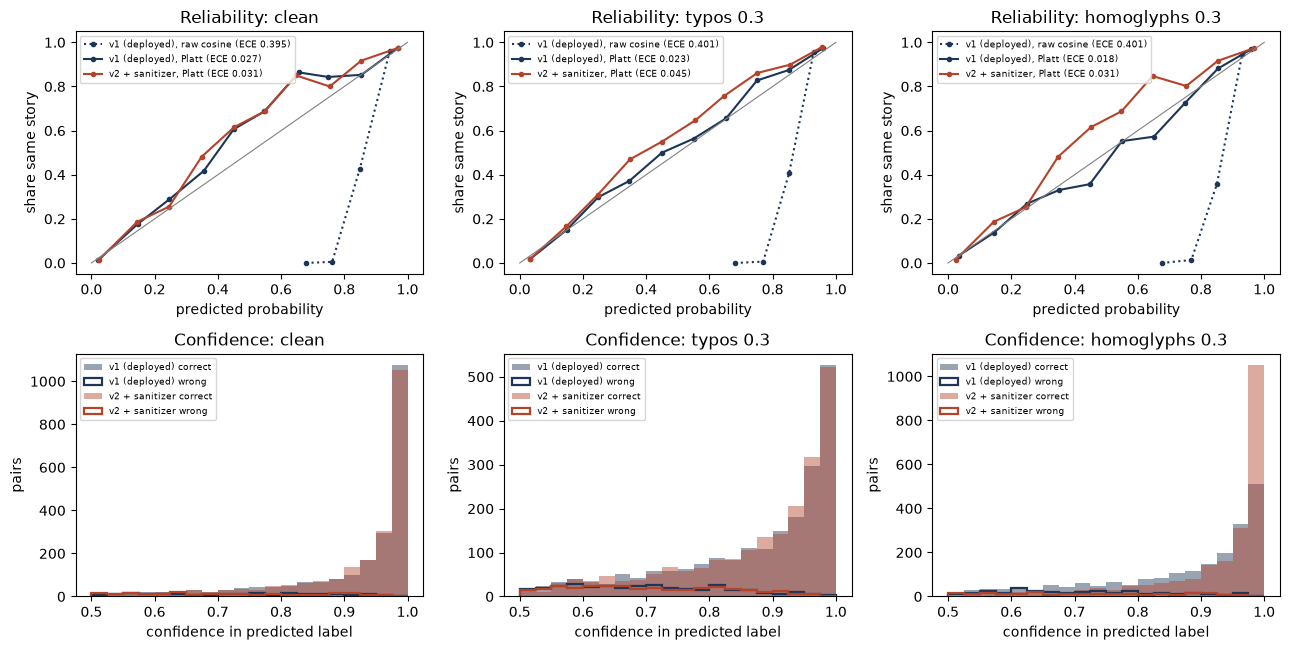

model                      v1 (deployed)  v2 + sanitizer
case           mapping                                  
clean          Platt               0.027           0.031
               raw cosine          0.395           0.407
homoglyphs 0.3 Platt               0.018           0.031
               raw cosine          0.401           0.406
typos 0.3      Platt               0.023           0.045
               raw cosine          0.401           0.405

In [26]:
CAL_CASES = [('clean', None), ('typos', 0.3), ('homoglyphs', 0.3)]
fig, axes = plt.subplots(2, 3, figsize=(13, 6.6))
rel_rows = []
for col, (kind, st) in enumerate(CAL_CASES):
    df = TEST if kind == 'clean' else PERTURBED[(kind, st)]
    yy = df.label.values
    ax = axes[0, col]
    for name in MAIN:
        p = PIPES[name]
        s = CLEAN[name] if kind == 'clean' else SCORES[(name, kind, st, SEED)]
        for lab, how in [('raw cosine', np.clip((s + 1) / 2, 0, 1)), ('Platt', p.prob(s))]:
            e, rel = ece(yy, how, bins=10)
            rel_rows.append({'model': name, 'case': f'{kind} {st or ""}'.strip(), 'mapping': lab, 'ece': e})
            if name == 'v1 (deployed)' or lab == 'Platt':
                ax.plot(rel.confidence, rel.accuracy, marker='o', ms=3, color=COL[name], ls='-' if lab == 'Platt' else ':',
                        label=f'{name}, {lab} (ECE {e:.3f})')
    ax.plot([0, 1], [0, 1], color='grey', lw=0.8)
    ax.set(title=f'Reliability: {kind}{" " + str(st) if st else ""}', xlabel='predicted probability', ylabel='share same story')
    ax.legend(fontsize=6.5)
    ax = axes[1, col]
    for name in MAIN:
        p = PIPES[name]
        s = CLEAN[name] if kind == 'clean' else SCORES[(name, kind, st, SEED)]
        conf = p.prob(s)
        conf = np.where(conf >= p.prob([p.threshold])[0], conf, 1 - conf)    # confidence in the predicted label
        wrong = (s >= p.threshold).astype(int) != yy
        ax.hist(conf[~wrong], bins=20, range=(0.5, 1), alpha=0.45, color=COL[name], label=f'{name} correct')
        ax.hist(conf[wrong], bins=20, range=(0.5, 1), histtype='step', lw=1.6, color=COL[name], label=f'{name} wrong')
    ax.set(title=f'Confidence: {kind}{" " + str(st) if st else ""}', xlabel='confidence in predicted label', ylabel='pairs')
    ax.legend(fontsize=6.5)
plt.tight_layout(); plt.savefig(O / 'figures' / 'calibration.png', dpi=200); plt.show()
calib = pd.DataFrame(rel_rows); calib.to_csv(O / 'calibration_ece.csv', index=False)
calib.pivot_table(index=['case', 'mapping'], columns='model', values='ece').round(3)

## Card-level grouping (ARI vs Google's cards) under corruption

In [27]:
pages = front_pages()
if SMOKE:
    pages = pages[:15]

def grouping(pipe, pages, fn=None, st=None):
    rng = np.random.default_rng(SEED)
    rows = []
    for heads, truth, ed in pages:
        h = [fn(x, rng, st) for x in heads] if fn else heads
        if len(h) < 2:
            pred = np.zeros(len(h), int)
        else:
            E = pipe.scorer.embed(pipe.prep(h))
            S = E @ E.T
            S = np.asarray(S.todense()) if hasattr(S, 'todense') else S
            pred = AgglomerativeClustering(n_clusters=None, metric='precomputed', linkage='average',
                                           distance_threshold=1 - pipe.threshold).fit_predict(np.clip(1 - S, 0, None))
        google = {frozenset(np.where(truth == k)[0]) for k in set(truth)}
        ours = {frozenset(np.where(pred == k)[0]) for k in set(pred)}
        rows.append((adjusted_rand_score(truth, pred), len(google & ours), len(google)))
    r = np.array(rows)
    return r[:, 0].mean(), r[:, 1].sum() / r[:, 2].sum()

rows = []
for kind, fn, st in [('clean', None, None), ('typos', char_noise, 0.3), ('homoglyphs', homoglyph, 0.3),
                     ('word dropout', word_dropout, 0.2), ('prefix added', add_prefix, None)]:
    for name in ['TF-IDF', 'v1 (deployed)', 'v2 + sanitizer']:
        ari, exact = grouping(PIPES[name], pages, fn, st)
        rows.append({'model': name, 'corruption': kind, 'strength': st, 'ARI': ari, 'exact_cards': exact})
cards = pd.DataFrame(rows); cards.to_csv(O / 'grouping_under_corruption.csv', index=False)
print(len(pages), 'pages'); cards.pivot(index='corruption', columns='model', values='ARI').round(3)

112 pages


model,TF-IDF,v1 (deployed),v2 + sanitizer
corruption,,,
clean,0.640,0.776,0.812
homoglyphs,0.536,0.651,0.812
prefix added,0.478,0.755,0.812
typos,0.510,0.634,0.686
word dropout,0.556,0.692,0.706


## 2.4b Latency (p50/p90 per front page), memory and size

In [28]:
proc = psutil.Process()
lat_pages = [h for h, _, _ in pages if len(h) >= 2]
rng = np.random.default_rng(SEED)
WORKLOADS = {
    'clean': lat_pages,
    'corrupted (typos 0.3)': [[char_noise(x, rng, 0.3) for x in h] for h in lat_pages],
    'adversarial (homoglyphs 0.3)': [[homoglyph(x, rng, 0.3) for x in h] for h in lat_pages],
}
rows = []
REP = 30 if SMOKE else 200
for name in ['TF-IDF', 'v1 (deployed)', 'v1 + sanitizer', 'v2 (augmented)', 'v2 + sanitizer']:
    for wl, pg in WORKLOADS.items():
        rows.append({'model': name, 'input': wl, **page_latency(PIPES[name], pg, repeats=REP)})
lat = pd.DataFrame(rows); lat.to_csv(O / 'latency.csv', index=False)

def dir_mb(p):
    p = Path(p)
    return sum(f.stat().st_size for f in p.rglob('*') if f.is_file()) / 1e6 if p.exists() else np.nan
t0 = time.perf_counter(); n = 2000
_ = [sanitize(x) for x in (TEST.headline_a.tolist() * 2)[:n]]
san_us = (time.perf_counter() - t0) / n * 1e6
size = pd.DataFrame([
    {'model': 'v1 (deployed)', 'disk_MB': dir_mb(V1_PATH), 'params_M': sum(p.numel() for p in v1.model.parameters()) / 1e6},
    {'model': 'v2 (augmented)', 'disk_MB': dir_mb(v2_path), 'params_M': sum(p.numel() for p in v2.model.parameters()) / 1e6},
])
EFF = {'process_rss_GB_after_both_models': proc.memory_info().rss / 1e9, 'sanitizer_us_per_headline': san_us,
       'platt_parameters': 2, 'hardware': HW}
if DEVICE == 'cuda':
    EFF['peak_vram_GB'] = torch.cuda.max_memory_allocated() / 1e9
size.to_csv(O / 'model_size.csv', index=False); json.dump(EFF, open(O / 'efficiency.json', 'w'), indent=2, default=str)
display(size.round(1)); print(EFF)
lat.pivot(index='model', columns='input', values='p50_ms').round(1)

,model,disk_MB,params_M
0,v1 (deployed),487.7,117.7
1,v2 (augmented),487.7,117.7


{'process_rss_GB_after_both_models': 1.322123264, 'sanitizer_us_per_headline': 18.846700000722194, 'platt_parameters': 2, 'hardware': {'device': 'cuda', 'cpu': 'Intel64 Family 6 Model 151 Stepping 2, GenuineIntel', 'threads': 12, 'gpu': 'NVIDIA GeForce RTX 3060', 'torch': '2.14.1+cu126', 'sentence_transformers': '6.3.0', 'smoke': False}, 'peak_vram_GB': 3.17780736}


input,adversarial (homoglyphs 0.3),clean,corrupted (typos 0.3)
model,,,
TF-IDF,0.6,0.6,0.6
v1 (deployed),8.7,8.2,8.4
v1 + sanitizer,8.8,8.7,8.3
v2 (augmented),8.7,8.8,8.4
v2 + sanitizer,8.9,8.6,8.6


## 2.4c Failure cases

Candidates: test pairs the deployed v1 gets wrong (clean or under one corruption/attack), with what v2 + sanitizer says.
`resolved = True` when v2 + sanitizer gets the pair right. The report table is picked from `failure_candidates.csv`.

In [29]:
WHY = {'clean': 'wording differs / same names in different stories', 'typos': 'misspelt key words',
       'word dropout': 'key words lost', 'homoglyphs': 'look-alike letters + invisible characters',
       'accents stripped': 'accents removed', 'case changed': 'all caps / lower case', 'prefix added': 'live/opinion prefix',
       'entity stuffing': "other story's key terms appended"}
FIX = {'clean': 'abstain near threshold; hand-checked labels', 'typos': 'augmentation (v2)', 'word dropout': 'augmentation (v2)',
       'homoglyphs': 'sanitizer (confusable folding, Cf removal)', 'accents stripped': 'augmentation (v2)',
       'case changed': 'augmentation (v2)', 'prefix added': 'sanitizer + augmentation',
       'entity stuffing': 'abstention band; per-outlet rate limit; flag appended term lists'}
cases = [('clean', 0, TEST)] + [(k, st, PERTURBED[(k, st)]) for k, st in
         [('typos', 0.3), ('word dropout', 0.3), ('homoglyphs', 0.3), ('accents stripped', None), ('case changed', None),
          ('prefix added', None), ('entity stuffing', 3)]]
rows = []
for kind, st, df in cases:
    key = lambda n: CLEAN[n] if kind == 'clean' else SCORES[(n, kind, st if st is not None else 1, SEED)] if kind != 'entity stuffing' else SCORES[(n, kind, st, SEED)]
    s1, s2 = key('v1 (deployed)'), key('v2 + sanitizer')
    p1, p2 = PIPES['v1 (deployed)'], PIPES['v2 + sanitizer']
    yy = df.label.values
    wrong = (s1 >= p1.threshold).astype(int) != yy
    if kind != 'clean':
        wrong &= ((CLEAN['v1 (deployed)'] >= p1.threshold).astype(int) == yy)     # only failures caused by the corruption
    for i in np.where(wrong)[0]:
        rows.append({'case': kind, 'strength': st, 'headline_a_seen': df.headline_a.iloc[i], 'headline_b_seen': df.headline_b.iloc[i],
                     'headline_a_original': TEST.headline_a.iloc[i], 'headline_b_original': TEST.headline_b.iloc[i],
                     'edition': TEST.edition.iloc[i], 'expected': 'same' if yy[i] else 'different',
                     'v1_pred': 'same' if s1[i] >= p1.threshold else 'different', 'v1_prob_same': float(p1.prob([s1[i]])[0]),
                     'v2s_pred': 'same' if s2[i] >= p2.threshold else 'different', 'v2s_prob_same': float(p2.prob([s2[i]])[0]),
                     'resolved': bool((s2[i] >= p2.threshold) == bool(yy[i])), 'why': WHY[kind], 'mitigation': FIX[kind]})
fails = pd.DataFrame(rows)
fails['v1_confidence'] = np.where(fails.v1_pred == 'same', fails.v1_prob_same, 1 - fails.v1_prob_same)
fails.to_csv(O / 'failure_candidates.csv', index=False)
# table for the report: per case, the most confident v1 failure (prefer one resolved and one not, across cases)
pick = (fails.sort_values('v1_confidence', ascending=False).groupby(['case', 'resolved']).head(1)
        .sort_values(['resolved', 'v1_confidence'], ascending=[False, False]))
picked = pd.concat([pick[pick.resolved].head(5), pick[~pick.resolved].head(4)])
picked.to_csv(O / 'failure_table.csv', index=False)
print(fails.groupby('case').resolved.agg(['size', 'mean']).round(3))
picked[['case', 'headline_a_seen', 'headline_b_seen', 'expected', 'v1_pred', 'v1_confidence', 'v2s_pred', 'resolved']]

                  size   mean
case                         
accents stripped     8  0.500
case changed       211  0.588
clean              214  0.201
entity stuffing    511  0.286
homoglyphs         211  0.934
prefix added        53  0.943
typos              202  0.406
word dropout       282  0.195


,case,headline_a_seen,headline_b_seen,expected,v1_pred,v1_confidence,v2s_pred,resolved
740,homoglyphs,'Ridiculous lack of leadership': Jeromy Fa­rkа...,Canada’s Carney says Alberta is ‘essential’ as...,same,different,0.972082,same,True
1085,case changed,TRUMP LASHES OUT AT SUPREME COURT JUSTICES AFT...,"in controversial mail-in ballot ruling, trump ...",same,different,0.958113,same,True
1272,entity stuffing,Impôts de l'ex-maire Gilles Vaillancourt: la V...,Christine Fréchette réalise-t-elle l’impensable?,different,same,0.914847,different,True
1154,prefix added,Dossier | Trump pauses 50 percent tariffs on C...,Dossier | PQ delays push to hold sovereignty r...,different,same,0.812840,different,True
161,clean,Carney says he's still 'regularly' speaking wi...,Canada needs millions of drones to upgrade fig...,different,same,0.812711,different,True
465,word dropout,residential,watching’: tribunal school system opens in Mon...,same,different,0.994400,different,False
1528,entity stuffing,Opinion | There’s Only One Winner of a Trade W...,What caused the catastrophic flooding on the N...,different,same,0.990985,same,False
79,clean,"Ce qu’on suit ce jeudi | Mark Carney, incendie...",Le Canada soulève des préoccupations en matièr...,same,different,0.979715,different,False
230,typos,"Trupm rejette la réponse dde l’ran, le pétrile...",Conlfit au Moyen-Orient | Trump rejette la rép...,same,different,0.977736,different,False


## Consistency with Milestone 2

Milestone 2's recorded results next to this run, written to `m2_consistency.csv`. TF-IDF must match exactly. v1 matches
only if `models/minilm_finetuned` is the original Milestone 2 model. Training time and latency come from different
machines, so they are a reference, not a comparison.

In [30]:
g = cards.set_index(['corruption', 'model'])
cm = clean.set_index('model')
rows = []
for name, key in [('TF-IDF', 'TF-IDF'), ('v1 (deployed)', 'v1')]:
    m2p, m2g = M2['pairs'].get(key, {}), M2['grouping'].get(key, {})
    for metric, m2v, m3v in [('val threshold', m2p.get('val', {}).get('threshold'), round(PIPES[name].threshold, 4)),
                             ('test F1', m2p.get('test', {}).get('f1'), cm.loc[name, 'f1']),
                             ('test PR-AUC', m2p.get('test', {}).get('pr_auc'), cm.loc[name, 'pr_auc']),
                             ('test F1, English', None, cm.loc[name, 'f1_en']),
                             ('card ARI', m2g.get('ARI'), g.loc[('clean', name), 'ARI']),
                             ('exact cards', m2g.get('exact_cards'), g.loc[('clean', name), 'exact_cards'])]:
        if m2v is None:
            continue
        rows.append({'model': name, 'metric': metric, 'milestone2': m2v, 'milestone3': m3v,
                     'difference': m3v - m2v, 'match': abs(m3v - m2v) < 1e-3})
cons = pd.DataFrame(rows)
ref = pd.DataFrame([
    {'item': 'v1 training time (min)', 'milestone2': M2['train_minutes'], 'milestone2_hardware': M2['train_hardware'],
     'milestone3': json.load(open(O / 'v2_train_config.json'))['minutes'], 'milestone3_hardware': HW['gpu'] or HW['device'],
     'note': 'Milestone 3 value is v2 (same recipe + augmentation)'},
    {'item': 'v1 page latency p50 (ms)', 'milestone2': (M2['page_latency'] or {}).get('p50_ms'),
     'milestone2_hardware': (M2['page_latency'] or {}).get('hardware'),
     'milestone3': lat.set_index(['model', 'input']).loc[('v1 (deployed)', 'clean'), 'p50_ms'],
     'milestone3_hardware': HW['gpu'] or HW['device'], 'note': 'different machines'},
])
cons.to_csv(O / 'm2_consistency.csv', index=False)
ref.to_csv(O / 'm2_reference.csv', index=False)
display(cons.round(4)); display(ref)

,model,metric,milestone2,milestone3,difference,match
0,TF-IDF,val threshold,0.0424,0.0424,0.0,True
1,TF-IDF,test F1,0.7680,0.7680,0.0,True
2,TF-IDF,test PR-AUC,0.8460,0.8460,0.0,True
3,TF-IDF,card ARI,0.6396,0.6396,0.0,True
4,TF-IDF,exact cards,0.5759,0.5759,0.0,True
5,v1 (deployed),val threshold,0.7244,0.7244,0.0,True
6,v1 (deployed),test F1,0.9059,0.9059,0.0,True
7,v1 (deployed),test PR-AUC,0.9658,0.9658,0.0,True
8,v1 (deployed),card ARI,0.7761,0.7761,0.0,True
9,v1 (deployed),exact cards,0.6719,0.6719,0.0,True


,item,milestone2,milestone2_hardware,milestone3,milestone3_hardware,note
0,v1 training time (min),1.50,NVIDIA GeForce RTX 3080,3.30000,NVIDIA GeForce RTX 3060,Milestone 3 value is v2 (same recipe + augment...
1,v1 page latency p50 (ms),16.23,"Apple M4 Max CPU (Milestone 2, Section 3)",8.24955,NVIDIA GeForce RTX 3060,different machines
